# AttentionBaseNet for Cross-Subject Motor-Imagery Decoding

## 1. Objective
This module evaluates a channel-attention CNN (`AttentionBaseNet`) for four-class motor-imagery EEG decoding under a strict leave-one-subject-out (LOSO) validation protocol.

Because the BCI Competition IV-2a dataset contains exactly 9 subjects, the LOSO protocol rotates through 9 folds. In each fold:
- One participant is held out for final testing.
- One distinct participant is used for early stopping (validation).
- The remaining seven participants form the training set. 
No epochs from the test participant are used for model fitting, augmentation, early stopping, or checkpoint selection.

## 2. Attention and augmentation ablation
The SE (Squeeze-and-Excitation) module adaptively reweights learned feature channels. Its weights are treated as model components, not as direct evidence of cortical source localisation or neurophysiological causality.

The primary ablation compares:
- **NoAug:** training on original standardized epochs.
- **Aug:** identical training data plus a training-only Gaussian-noise copy ($\sigma = 0.05$). Gaussian noise is added after per-trial, per-channel Z-score normalisation. 

To assess true cross-subject robustness, performance is reported for each held-out test subject individually, and overall conclusions are drawn from the **mean $\pm$ standard deviation** across all 9 folds, rather than just aggregated accuracy.

## Setup, Path check e costants

In [1]:
import os
import time
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader
import mne
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
from scipy.stats import wilcoxon
from braindecode.models import AttentionBaseNet

# 1. Reproducibility
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# 2. Directories
os.makedirs('saved_models', exist_ok=True)
os.makedirs('saved_plots', exist_ok=True)

CLEAN_DATA_DIR = os.path.join('.', 'cleaned_data_1_40')
EVENT_ID = {'left': 1, 'right': 2, 'foot': 3, 'tongue': 4}
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Foot', 'Tongue']
T_MIN, T_MAX = 0.5, 3.5
ALL_SUBJECTS = [f'A{i:02d}T' for i in range(1, 10)]

# 3. Path Verification
print("Checking file paths...")
all_files_exist = True
for sub in ALL_SUBJECTS:
    path = os.path.join(CLEAN_DATA_DIR, f"{sub}_clean_1_40_raw.fif")
    exists = os.path.exists(path)
    if not exists:
        print(f"MISSING: {path}")
        all_files_exist = False
assert all_files_exist, "Missing data files. Check paths before proceeding."
print("All files found.")

Using device: cpu
Checking file paths...
All files found.


## Dynamic load and tensor preparation

In [2]:
def load_subject(subject_id):
    """Loads raw .fif, epochs, and applies per-trial Z-score normalisation."""
    file_path = os.path.join(CLEAN_DATA_DIR, f'{subject_id}_clean_1_40_raw.fif')
    raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)
    raw.pick(['eeg'])
    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose=False)
    epochs = mne.Epochs(raw, events, event_id=EVENT_ID, tmin=T_MIN, tmax=T_MAX,
                        baseline=None, preload=True, verbose=False)
    
    X = epochs.get_data(copy=True).astype(np.float32)
    y = epochs.events[:, -1] - 1
    
    # Z-score per trial, per channel
    X = (X - X.mean(axis=-1, keepdims=True)) / (X.std(axis=-1, keepdims=True) + 1e-8)
    return X, y

data = {}
print("Loading all subjects into memory...")
for sub in ALL_SUBJECTS:
    data[sub] = load_subject(sub)
print("Loading complete.")

# Dynamically derive input shapes
X_example, _ = data[ALL_SUBJECTS[0]]
N_CHANS = X_example.shape[1]
N_TIMES = X_example.shape[2]
N_CLASSES = len(CLASS_NAMES)
print(f"Derived Input Shape: {N_CHANS} channels x {N_TIMES} samples")

def stack(subjects):
    """Concatenates numpy arrays for a given list of subjects."""
    X_stacked = np.concatenate([data[s][0] for s in subjects], axis=0)
    y_stacked = np.concatenate([data[s][1] for s in subjects], axis=0)
    return X_stacked, y_stacked

def prep_tensors(X, y):
    """Removes trailing dummy dimensions and converts to PyTorch tensors."""
    if len(X.shape) == 4: 
        X = np.squeeze(X, axis=-1)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

def add_gaussian_noise(X_torch, std=0.05):
    noise = torch.randn_like(X_torch) * std
    return X_torch + noise

Loading all subjects into memory...
Loading complete.
Derived Input Shape: 22 channels x 751 samples


## Training engine (deepcopy and loss weighting)

In [3]:
BATCH_SIZE = 32

def train_model_fold(model, X_tr, y_tr, X_va, y_va, epochs=60, patience=15, lr=1e-3, augment=False):
    """Trains one LOSO fold and restores the best validation-loss checkpoint."""
    
    if augment:
        X_tr_noisy = add_gaussian_noise(X_tr, std=0.05)
        X_tr = torch.cat([X_tr, X_tr_noisy], dim=0)
        y_tr = torch.cat([y_tr, y_tr], dim=0)
        
    train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_va, y_va), batch_size=BATCH_SIZE, shuffle=False)
    
    model = model.to(device)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    best_val_loss = float("inf")
    best_model_state = None
    patience_counter = 0
    
    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            
        model.eval()
        total_val_loss = 0.0
        total_val_samples = 0
        
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                
                logits = model(X_batch)
                batch_loss = criterion(logits, y_batch)
                
                total_val_loss += batch_loss.item() * len(y_batch)
                total_val_samples += len(y_batch)
                
        val_loss = total_val_loss / total_val_samples
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
                
    model.load_state_dict(best_model_state)
    return model, best_val_loss, epoch + 1

## LOSO Loop and full checkpoint save

Starting Leave-One-Subject-Out (LOSO) Evaluation with Detailed Reporting...


Fold 1/9 | Test Subject: A01T | Validation Subject: A02T

--- Training Condition: NoAug ---
Classification Report for Subject A01T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.64      0.67      0.65        72
  Right Hand       0.70      0.65      0.68        72
        Foot       0.55      0.58      0.57        72
      Tongue       0.61      0.60      0.61        72

    accuracy                           0.62       288
   macro avg       0.63      0.62      0.63       288
weighted avg       0.63      0.62      0.63       288


--- Training Condition: Aug ---
Classification Report for Subject A01T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.59      0.58      0.59        72
  Right Hand       0.61      0.62      0.62        72
        Foot       0.51      0.43      0.47        72
      Tongue       0.62      0.71      0.66        

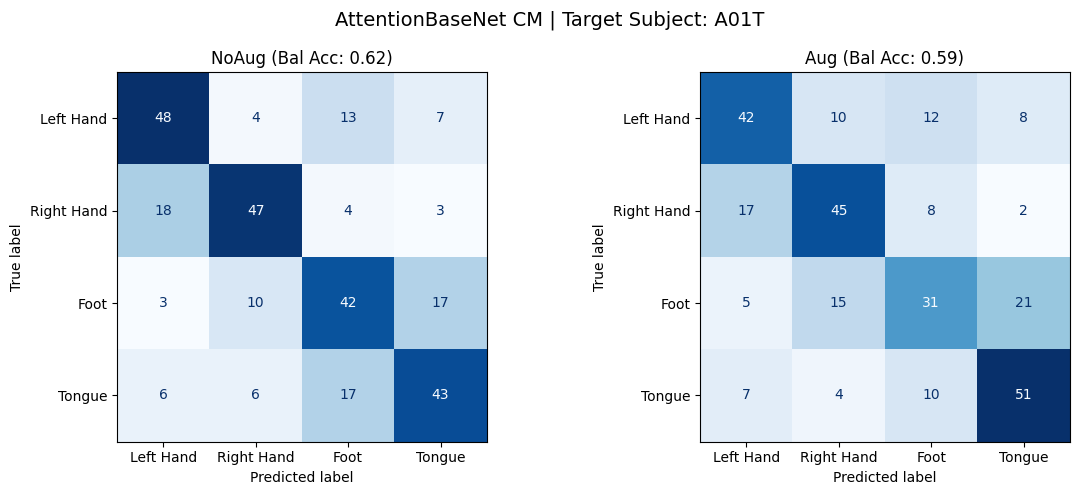


Fold 2/9 | Test Subject: A02T | Validation Subject: A03T

--- Training Condition: NoAug ---
Classification Report for Subject A02T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.44      0.33      0.38        72
  Right Hand       0.40      0.33      0.36        72
        Foot       0.31      0.50      0.38        72
      Tongue       0.44      0.33      0.38        72

    accuracy                           0.38       288
   macro avg       0.39      0.37      0.37       288
weighted avg       0.39      0.38      0.37       288


--- Training Condition: Aug ---
Classification Report for Subject A02T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.39      0.39      0.39        72
  Right Hand       0.50      0.17      0.25        72
        Foot       0.32      0.61      0.42        72
      Tongue       0.43      0.33      0.38        72

    accuracy                           0.38       288
   macro avg       

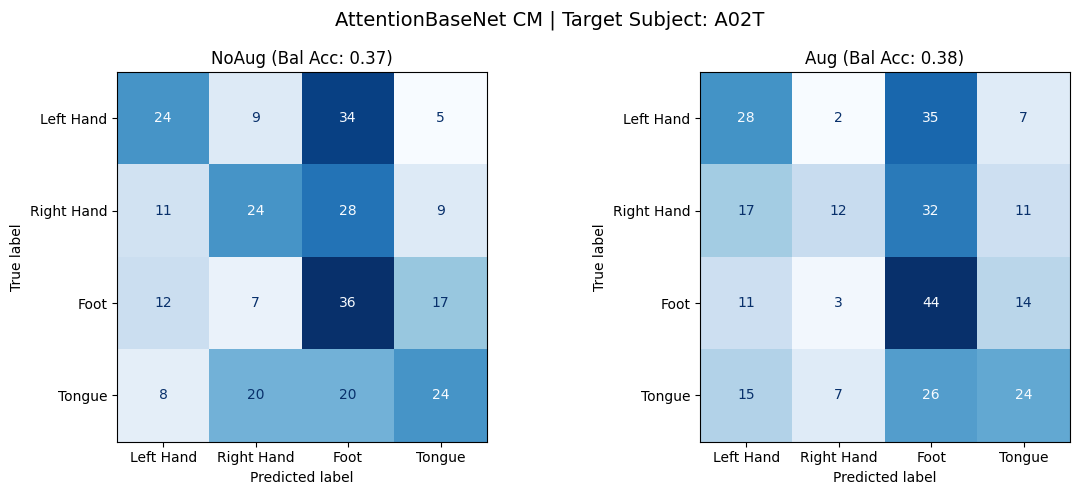


Fold 3/9 | Test Subject: A03T | Validation Subject: A04T

--- Training Condition: NoAug ---
Classification Report for Subject A03T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.73      0.64      0.68        72
  Right Hand       0.56      0.74      0.63        72
        Foot       0.58      0.54      0.56        72
      Tongue       0.68      0.60      0.64        72

    accuracy                           0.63       288
   macro avg       0.64      0.63      0.63       288
weighted avg       0.64      0.63      0.63       288


--- Training Condition: Aug ---
Classification Report for Subject A03T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.76      0.58      0.66        72
  Right Hand       0.55      0.74      0.63        72
        Foot       0.61      0.57      0.59        72
      Tongue       0.64      0.61      0.62        72

    accuracy                           0.62       288
   macro avg       

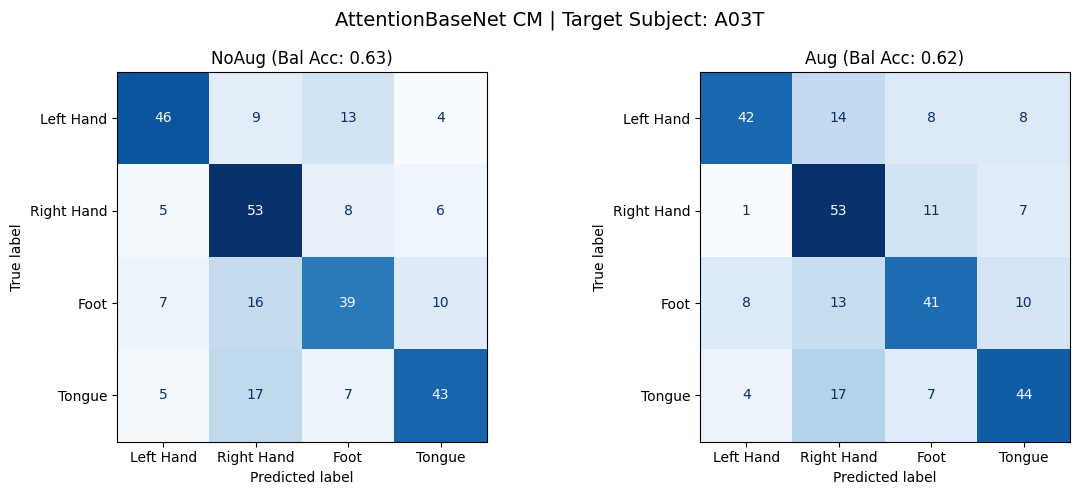


Fold 4/9 | Test Subject: A04T | Validation Subject: A05T

--- Training Condition: NoAug ---
Classification Report for Subject A04T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.40      0.31      0.35        72
  Right Hand       0.37      0.29      0.33        72
        Foot       0.37      0.54      0.44        72
      Tongue       0.56      0.54      0.55        72

    accuracy                           0.42       288
   macro avg       0.42      0.42      0.41       288
weighted avg       0.42      0.42      0.41       288


--- Training Condition: Aug ---
Classification Report for Subject A04T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.51      0.33      0.40        72
  Right Hand       0.36      0.64      0.46        72
        Foot       0.63      0.33      0.44        72
      Tongue       0.57      0.60      0.59        72

    accuracy                           0.48       288
   macro avg       

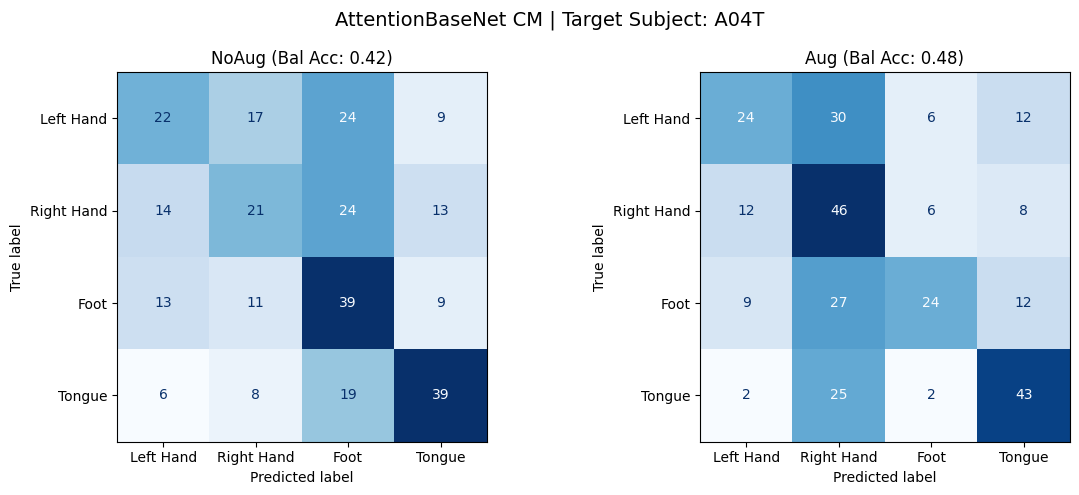


Fold 5/9 | Test Subject: A05T | Validation Subject: A06T

--- Training Condition: NoAug ---
Classification Report for Subject A05T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.33      0.43      0.37        72
  Right Hand       0.34      0.67      0.45        72
        Foot       0.73      0.31      0.43        72
      Tongue       0.52      0.17      0.25        72

    accuracy                           0.39       288
   macro avg       0.48      0.39      0.38       288
weighted avg       0.48      0.39      0.38       288


--- Training Condition: Aug ---
Classification Report for Subject A05T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.25      0.36      0.29        72
  Right Hand       0.25      0.54      0.34        72
        Foot       0.94      0.24      0.38        72
      Tongue       0.57      0.06      0.10        72

    accuracy                           0.30       288
   macro avg       

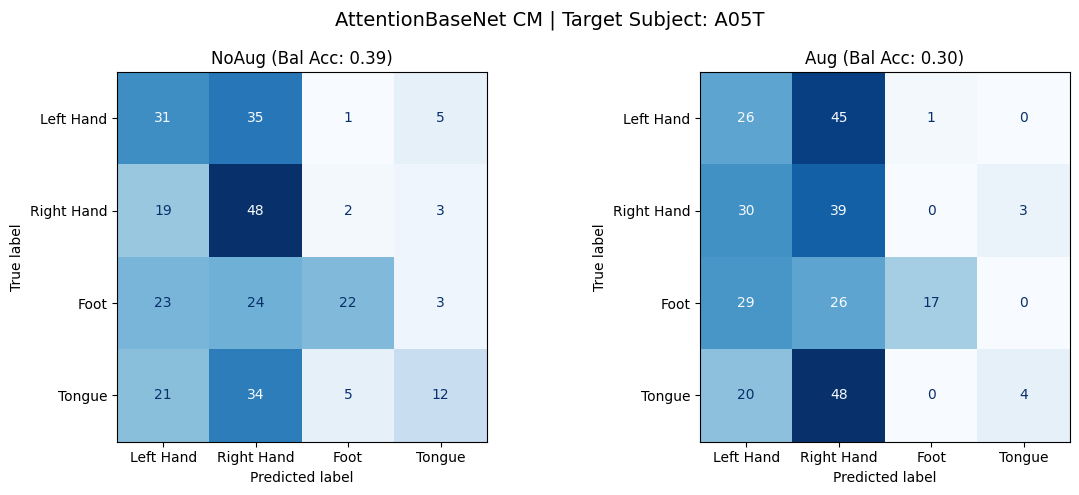


Fold 6/9 | Test Subject: A06T | Validation Subject: A07T

--- Training Condition: NoAug ---
Classification Report for Subject A06T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.77      0.42      0.54        72
  Right Hand       0.70      0.26      0.38        72
        Foot       0.43      0.64      0.52        72
      Tongue       0.41      0.67      0.51        72

    accuracy                           0.50       288
   macro avg       0.58      0.50      0.49       288
weighted avg       0.58      0.50      0.49       288


--- Training Condition: Aug ---
Classification Report for Subject A06T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.82      0.32      0.46        72
  Right Hand       0.78      0.25      0.38        72
        Foot       0.39      0.82      0.53        72
      Tongue       0.49      0.58      0.53        72

    accuracy                           0.49       288
   macro avg       

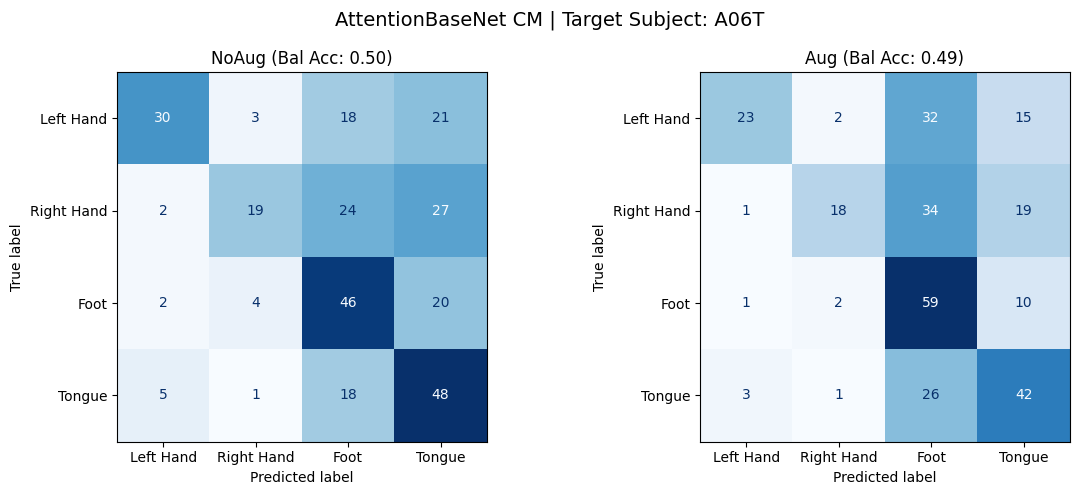


Fold 7/9 | Test Subject: A07T | Validation Subject: A08T

--- Training Condition: NoAug ---
Classification Report for Subject A07T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.40      0.61      0.49        72
  Right Hand       0.49      0.38      0.43        72
        Foot       0.57      0.54      0.56        72
      Tongue       0.57      0.44      0.50        72

    accuracy                           0.49       288
   macro avg       0.51      0.49      0.49       288
weighted avg       0.51      0.49      0.49       288


--- Training Condition: Aug ---
Classification Report for Subject A07T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.49      0.56      0.52        72
  Right Hand       0.52      0.43      0.47        72
        Foot       0.56      0.61      0.58        72
      Tongue       0.57      0.53      0.55        72

    accuracy                           0.53       288
   macro avg       

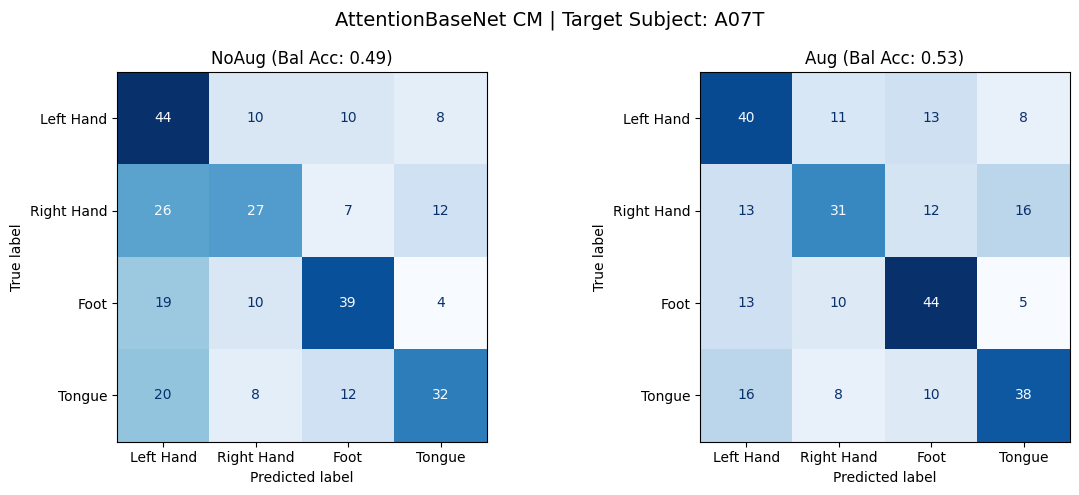


Fold 8/9 | Test Subject: A08T | Validation Subject: A09T

--- Training Condition: NoAug ---
Classification Report for Subject A08T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.53      0.83      0.65        72
  Right Hand       0.56      0.74      0.64        72
        Foot       0.75      0.17      0.27        72
      Tongue       0.74      0.67      0.70        72

    accuracy                           0.60       288
   macro avg       0.65      0.60      0.57       288
weighted avg       0.65      0.60      0.57       288


--- Training Condition: Aug ---
Classification Report for Subject A08T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.60      0.85      0.71        72
  Right Hand       0.72      0.69      0.71        72
        Foot       0.54      0.26      0.36        72
      Tongue       0.66      0.76      0.71        72

    accuracy                           0.64       288
   macro avg       

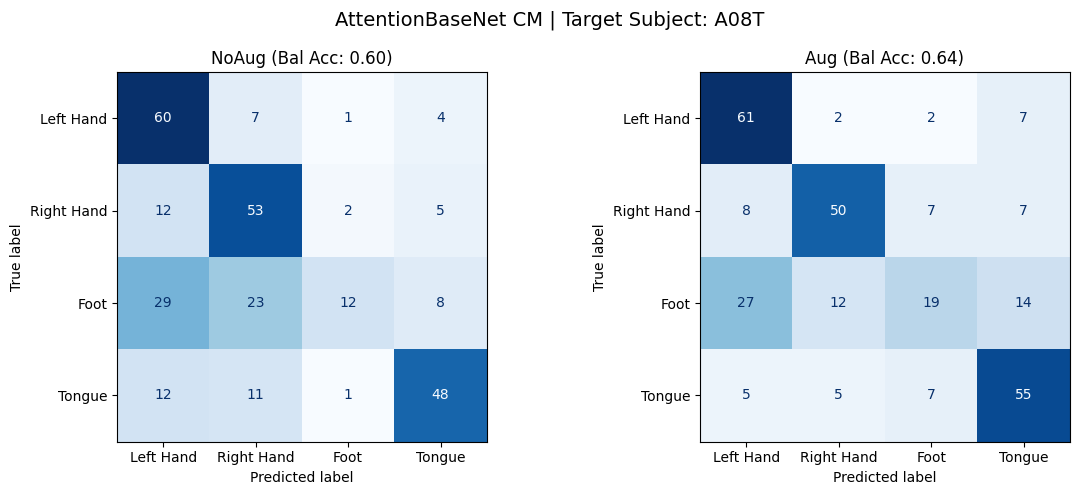


Fold 9/9 | Test Subject: A09T | Validation Subject: A01T

--- Training Condition: NoAug ---
Classification Report for Subject A09T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.80      0.62      0.70        72
  Right Hand       0.61      0.83      0.71        72
        Foot       0.69      0.38      0.49        72
      Tongue       0.68      0.90      0.78        72

    accuracy                           0.68       288
   macro avg       0.70      0.68      0.67       288
weighted avg       0.70      0.68      0.67       288


--- Training Condition: Aug ---
Classification Report for Subject A09T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.74      0.56      0.63        72
  Right Hand       0.56      0.86      0.68        72
        Foot       0.63      0.38      0.47        72
      Tongue       0.72      0.81      0.76        72

    accuracy                           0.65       288
   macro avg       

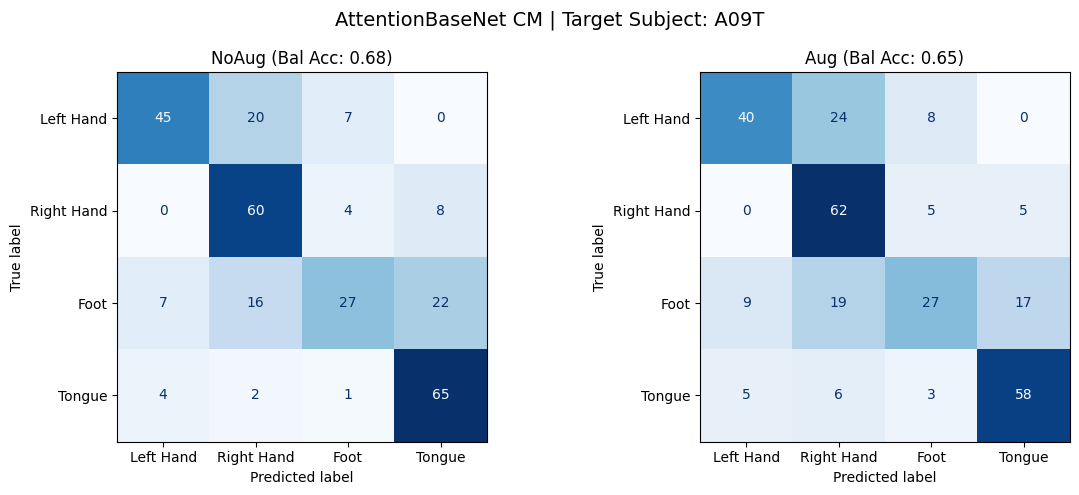


LOSO evaluation finished. Detailed results saved to 'loso_results.csv'.


In [4]:
loso_results = []
agg_preds = {'NoAug': [], 'Aug': []}
agg_targets = {'NoAug': [], 'Aug': []}

print("Starting Leave-One-Subject-Out (LOSO) Evaluation with Detailed Reporting...\n")

for i, test_sub in enumerate(ALL_SUBJECTS):
    val_sub = ALL_SUBJECTS[(i + 1) % len(ALL_SUBJECTS)]
    train_subs = [s for s in ALL_SUBJECTS if s not in (test_sub, val_sub)]
    
    print(f"\n{'='*60}\nFold {i+1}/9 | Test Subject: {test_sub} | Validation Subject: {val_sub}\n{'='*60}")
    
    X_tr_t, y_tr_t = prep_tensors(*stack(train_subs))
    X_va_t, y_va_t = prep_tensors(*stack([val_sub]))
    X_te_t, y_te_t = prep_tensors(*stack([test_sub]))
    te_loader = DataLoader(TensorDataset(X_te_t, y_te_t), batch_size=BATCH_SIZE, shuffle=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'AttentionBaseNet CM | Target Subject: {test_sub}', fontsize=14)
    
    for j, use_aug in enumerate([False, True]):
        cond_name = "Aug" if use_aug else "NoAug"
        print(f"\n--- Training Condition: {cond_name} ---")
        
        set_seed() 
        model = AttentionBaseNet(
            n_chans=N_CHANS,
            n_outputs=N_CLASSES,
            n_times=N_TIMES,
            attention_mode="se",
            drop_prob_inp=0.5,
            drop_prob_attn=0.5
        )
        
        start_time = time.time()
        best_model, best_val_loss, epochs_trained = train_model_fold(
            model, X_tr_t, y_tr_t, X_va_t, y_va_t, 
            epochs=60, patience=15, lr=0.001, augment=use_aug
        )
        train_time = time.time() - start_time
        
        # Save checkpoint
        checkpoint = {
            "model_name": "AttentionBaseNet",
            "attention_mode": "se",
            "test_subject": test_sub,
            "validation_subject": val_sub,
            "training_subjects": train_subs,
            "condition": cond_name,
            "seed": SEED,
            "n_chans": N_CHANS,
            "n_times": N_TIMES,
            "n_outputs": N_CLASSES,
            "learning_rate": 1e-3,
            "batch_size": BATCH_SIZE,
            "max_epochs": 60,
            "early_stopping_patience": 15,
            "best_validation_loss": best_val_loss,
            "epochs_trained": epochs_trained,
            "model_state_dict": best_model.state_dict(),
        }
        torch.save(checkpoint, f"saved_models/AttentionBaseNet_{test_sub}_{cond_name}.pth")
        
        # Inference
        best_model.eval()
        fold_preds, fold_targets = [], []
        with torch.no_grad():
            for X_batch, y_batch in te_loader:
                X_batch = X_batch.to(device)
                outputs = best_model(X_batch)
                _, predicted = torch.max(outputs.data, 1)
                fold_preds.extend(predicted.cpu().numpy())
                fold_targets.extend(y_batch.numpy())
                
        agg_preds[cond_name].extend(fold_preds)
        agg_targets[cond_name].extend(fold_targets)
        
        # Print complete classification report for this specific subject/experiment
        print(f"Classification Report for Subject {test_sub} ({cond_name}):")
        report_str = classification_report(fold_targets, fold_preds, target_names=CLASS_NAMES, zero_division=0)
        print(report_str)
        
        # Extract metrics into dictionary format
        report_dict = classification_report(fold_targets, fold_preds, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
        
        acc = accuracy_score(fold_targets, fold_preds)
        balanced_acc = balanced_accuracy_score(fold_targets, fold_preds)
        
        macro_prec = report_dict['macro avg']['precision']
        macro_rec = report_dict['macro avg']['recall']
        macro_f1 = report_dict['macro avg']['f1-score']
        
        weighted_prec = report_dict['weighted avg']['precision']
        weighted_rec = report_dict['weighted avg']['recall']
        weighted_f1 = report_dict['weighted avg']['f1-score']
        
        loso_results.append({
            "Test Subject": test_sub,
            "Validation Subject": val_sub,
            "Condition": cond_name,
            "Accuracy": acc,
            "Balanced Accuracy": balanced_acc,
            "Macro Precision": macro_prec,
            "Macro Recall": macro_rec,
            "Macro F1": macro_f1,
            "Weighted Precision": weighted_prec,
            "Weighted Recall": weighted_rec,
            "Weighted F1": weighted_f1,
            "Train Time (s)": round(train_time, 1),
            "Best Val Loss": round(best_val_loss, 4),
            "Epochs Trained": epochs_trained
        })
        
        # Plot confusion matrix subplot
        cm = confusion_matrix(fold_targets, fold_preds)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
        disp.plot(ax=axes[j], cmap='Blues', colorbar=False, values_format='d')
        axes[j].set_title(f'{cond_name} (Bal Acc: {balanced_acc:.2f})')

    plt.tight_layout()
    plt.savefig(f'saved_plots/CM_{test_sub}_AttentionBaseNet.png')
    plt.show()

# Save all detailed metrics to CSV
results_df = pd.DataFrame(loso_results)
results_df.to_csv("loso_results.csv", index=False)
print("\nLOSO evaluation finished. Detailed results saved to 'loso_results.csv'.")

## Aggregate descriptive analysis and paired exploration

In [5]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

# Load the previously saved results
results_df = pd.read_csv("loso_results.csv")

print("=== Cross-Subject Robustness (Mean +/- Std across 9 Folds) ===\n")

# Explicitly calculate and print Mean +/- Std for both conditions
for cond in ['NoAug', 'Aug']:
    cond_df = results_df[results_df['Condition'] == cond]
    mean_bal_acc = cond_df['Balanced Accuracy'].mean()
    std_bal_acc = cond_df['Balanced Accuracy'].std()
    mean_f1 = cond_df['Macro F1'].mean()
    std_f1 = cond_df['Macro F1'].std()
    
    print(f"[{cond}] Balanced Accuracy: {mean_bal_acc:.3f} +/- {std_bal_acc:.3f}")
    print(f"[{cond}] Macro F1 Score:    {mean_f1:.3f} +/- {std_f1:.3f}\n")

print("=== Paired Per-Subject Performance ===\n")

# Create a pivot table to show each subject's performance side-by-side
paired = results_df.pivot(
    index="Test Subject",
    columns="Condition",
    values=["Accuracy", "Balanced Accuracy", "Macro F1"]
)

# Rename columns for clarity
paired.columns = [f"{metric}_{condition}" for metric, condition in paired.columns]

# Calculate the Delta (Difference) for each subject
paired["BalancedAcc_Delta (Aug - NoAug)"] = paired["Balanced Accuracy_Aug"] - paired["Balanced Accuracy_NoAug"]
paired["MacroF1_Delta (Aug - NoAug)"] = paired["Macro F1_Aug"] - paired["Macro F1_NoAug"]

# Display the detailed per-subject table
display(paired[['Balanced Accuracy_NoAug', 'Balanced Accuracy_Aug', 'BalancedAcc_Delta (Aug - NoAug)',
                'Macro F1_NoAug', 'Macro F1_Aug', 'MacroF1_Delta (Aug - NoAug)']].round(3))

# Exploratory Wilcoxon signed-rank test on the deltas
delta = paired["BalancedAcc_Delta (Aug - NoAug)"]
stat, p_value = wilcoxon(delta)
print("\n=== Statistical Exploration ===")
print(f"Wilcoxon statistic on Balanced Accuracy Deltas: {stat:.3f}")
print(f"Exploratory paired p-value: {p_value:.4f}")
print("(Note: Given the small sample size of n=9 subjects, effect sizes and per-subject consistency are prioritized over binary significance claims).")

=== Cross-Subject Robustness (Mean +/- Std across 9 Folds) ===

[NoAug] Balanced Accuracy: 0.524 +/- 0.114
[NoAug] Macro F1 Score:    0.515 +/- 0.112

[Aug] Balanced Accuracy: 0.520 +/- 0.122
[Aug] Macro F1 Score:    0.509 +/- 0.126

=== Paired Per-Subject Performance ===



,Balanced Accuracy_NoAug,Balanced Accuracy_Aug,BalancedAcc_Delta (Aug - NoAug),Macro F1_NoAug,Macro F1_Aug,MacroF1_Delta (Aug - NoAug)
Test Subject,,,,,,
A01T,0.625,0.587,-0.038,0.626,0.583,-0.043
A02T,0.375,0.375,0.000,0.375,0.359,-0.015
A03T,0.628,0.625,-0.003,0.629,0.626,-0.003
A04T,0.420,0.476,0.056,0.415,0.471,0.056
A05T,0.392,0.299,-0.094,0.377,0.278,-0.099
A06T,0.497,0.493,-0.003,0.488,0.475,-0.013
A07T,0.493,0.531,0.038,0.492,0.530,0.038
A08T,0.601,0.642,0.042,0.565,0.620,0.055
A09T,0.684,0.649,-0.035,0.668,0.636,-0.032



=== Statistical Exploration ===
Wilcoxon statistic on Balanced Accuracy Deltas: 22.000
Exploratory paired p-value: 0.9766
(Note: Given the small sample size of n=9 subjects, effect sizes and per-subject consistency are prioritized over binary significance claims).


## Ablation visualization

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ACER\AppData\Local\Temp\ipykernel_4716\3652744754.py:8: SyntaxWarning: invalid escape sequence '\s'
  plt.bar(x + width / 2, plot_df["Balanced Accuracy_Aug"], width, label="Gaussian augmentation ($\sigma=0.05$)")


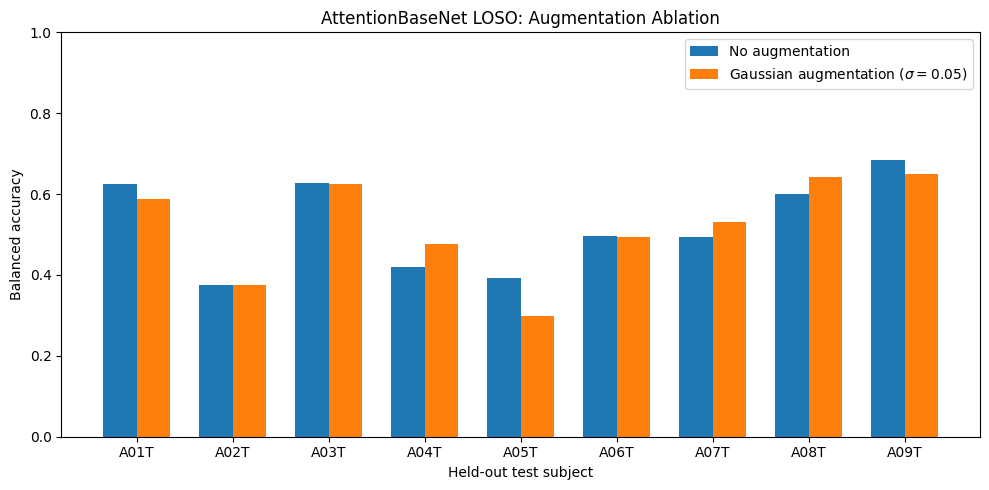

In [6]:
plot_df = paired.reset_index()

plt.figure(figsize=(10, 5))
x = np.arange(len(plot_df))
width = 0.35

plt.bar(x - width / 2, plot_df["Balanced Accuracy_NoAug"], width, label="No augmentation")
plt.bar(x + width / 2, plot_df["Balanced Accuracy_Aug"], width, label="Gaussian augmentation ($\sigma=0.05$)")

plt.xticks(x, plot_df["Test Subject"])
plt.ylim(0, 1)
plt.ylabel("Balanced accuracy")
plt.xlabel("Held-out test subject")
plt.title("AttentionBaseNet LOSO: Augmentation Ablation")
plt.legend()
plt.tight_layout()
plt.savefig("saved_plots/BalancedAccuracy_Augmentation_Ablation.png", dpi=200)
plt.show()

## **Conclusion and next steps: mooving beyond euclidean augmentation**


 The Leave-One-Subject-Out (LOSO) ablation study demonstrates that **Gaussian noise augmentation ($\sigma = 0.05$)  fails to systematically stabilize or improve cross-subject transfer** for `AttentionBaseNet`. 

 The overall balanced accuracy remained statistically unchanged ($0.520 \pm 0.122$ with augmentation vs. $0.524 \pm 0.114$ for the unaugmented baseline). Furthermore, a paired Wilcoxon signed-rank test confirmed that these minor performance fluctuations are statistically negligible and highly subject-dependent (\(p = 0.9766\)). 

 While the fixed noise injection slightly regularized training variance in specific validation configurations, it proved completely ineffective against the severe inter-subject variability inherent to the LOSO protocol even resulting in significant performance drops for certain individuals (e.g., test subject `A05T`).

### **Transition to riemannian geometry**
Given that standard Euclidean data augmentation cannot capture or mitigate these complex biological and domain shifts, **next step introduces Riemannian geometry principles**. 

Instead of treating the data in a flat Euclidean space, we will directly manipulate covariance matrices on the manifold, aiming for a more robust and geometrically sound cross-subject alignment.
